# DSCI 552 Homework 5

Name: Shirley (Xue) Feng  
GitHub Username: snowxxxue  
USC ID: 7145149057

## 1. Decision Trees as Interpretable Models

### 1(a) Load the Acute Inflammations Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.tree import export_text
from sklearn.preprocessing import LabelEncoder

In [2]:
file_path = "Data/diagnosis.data"

column_names = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "urethra_burning",
    "bladder_inflammation",
    "nephritis"
]

data = pd.read_csv(
    file_path,
    sep="\t",
    encoding="utf-16",
    header=None,
    decimal=","
)

data.columns = column_names

data.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,urethra_burning,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [3]:
data.shape

(120, 8)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   temperature           120 non-null    float64
 1   nausea                120 non-null    str    
 2   lumbar_pain           120 non-null    str    
 3   urine_pushing         120 non-null    str    
 4   micturition_pains     120 non-null    str    
 5   urethra_burning       120 non-null    str    
 6   bladder_inflammation  120 non-null    str    
 7   nephritis             120 non-null    str    
dtypes: float64(1), str(7)
memory usage: 9.7 KB


### 1(b) Build and Plot a Decision Tree

In [5]:
feature_names = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "urethra_burning"
]

target_names = [
    "bladder_inflammation",
    "nephritis"
]

X = data[feature_names].copy()

In [6]:
for column in feature_names[1:]:
    X[column] = X[column].map({
        "no": 0,
        "yes": 1
    })

X.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,urethra_burning
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0


In [7]:
data["class"] = (
    data["bladder_inflammation"]
    + "_"
    + data["nephritis"]
)

data["class"].head()

0     no_no
1    yes_no
2     no_no
3    yes_no
4     no_no
Name: class, dtype: str

In [8]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(data["class"])

print(label_encoder.classes_)

['no_no' 'no_yes' 'yes_no' 'yes_yes']


In [9]:
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [10]:
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())
print("Training accuracy:", model.score(X, y))

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0


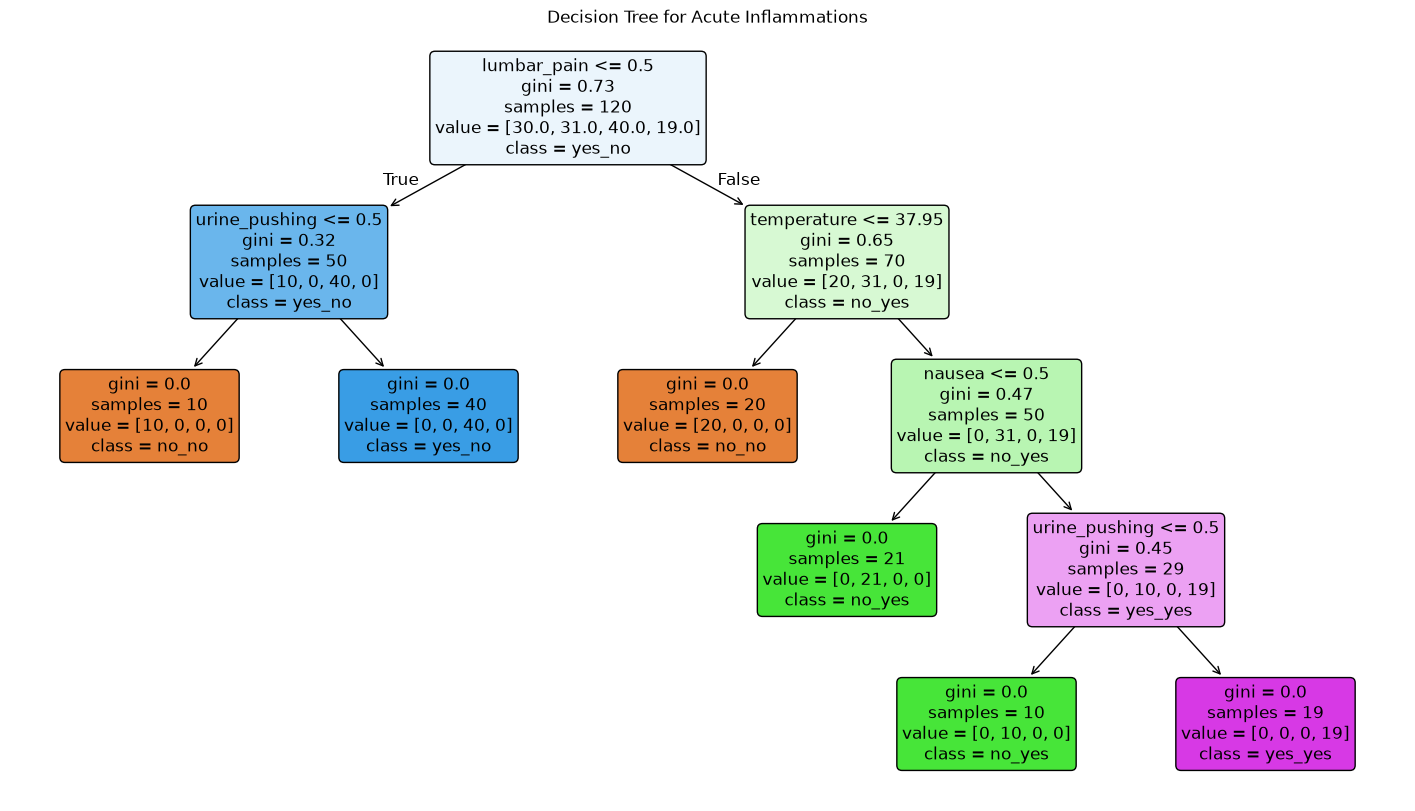

In [11]:
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    precision=2
)

plt.title("Decision Tree for Acute Inflammations")
plt.show()

### 1(c) Convert the Decision Tree into IF-THEN Rules

In [12]:
rules = export_text(
    model,
    feature_names=feature_names,
    decimals=2
)

print(rules)

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: 0
|   |--- urine_pushing >  0.50
|   |   |--- class: 2
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: 1
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 3



#### Rule 1

IF lumbar_pain = no
AND urine_pushing = no

THEN bladder_inflammation = no
AND nephritis = no

#### Rule 2

IF lumbar_pain = no
AND urine_pushing = yes

THEN bladder_inflammation = yes
AND nephritis = no

#### Rule 3

IF lumbar_pain = yes
AND temperature <= 37.95

THEN bladder_inflammation = no
AND nephritis = no

#### Rule 4

IF lumbar_pain = yes
AND temperature > 37.95
AND nausea = no

THEN bladder_inflammation = no
AND nephritis = yes

#### Rule 5

IF lumbar_pain = yes
AND temperature > 37.95
AND nausea = yes
AND urine_pushing = no

THEN bladder_inflammation = no
AND nephritis = yes

#### Rule 6

IF lumbar_pain = yes
AND temperature > 37.95
AND nausea = yes
AND urine_pushing = yes

THEN bladder_inflammation = yes
AND nephritis = yes

### 1(d) Cost-Complexity Pruning

In [13]:
X
y
model

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [14]:
pruning_path = model.cost_complexity_pruning_path(X, y)

ccp_alphas = pruning_path.ccp_alphas

In [15]:
for alpha in ccp_alphas:
    pruned_tree = DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=alpha
    )
    
    pruned_tree.fit(X, y)
    
    print(
        "alpha =", round(alpha, 4),
        "depth =", pruned_tree.get_depth(),
        "leaves =", pruned_tree.get_n_leaves(),
        "accuracy =", round(pruned_tree.score(X, y), 4)
    )

alpha = 0.0 depth = 4 leaves = 6 accuracy = 1.0
alpha = 0.0982 depth = 2 leaves = 4 accuracy = 0.8417
alpha = 0.1333 depth = 2 leaves = 3 accuracy = 0.7583
alpha = 0.182 depth = 1 leaves = 2 accuracy = 0.5917
alpha = 0.2229 depth = 0 leaves = 1 accuracy = 0.3333


In [16]:
pruned_alpha = ccp_alphas[1]

pruned_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    ccp_alpha=pruned_alpha
)

pruned_model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",np.float64(0....6666666666667)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative r

In [17]:
print("Selected alpha:", pruned_alpha)
print("Tree depth:", pruned_model.get_depth())
print("Number of leaves:", pruned_model.get_n_leaves())
print("Training accuracy:", pruned_model.score(X, y))

Selected alpha: 0.09816666666666667
Tree depth: 2
Number of leaves: 4
Training accuracy: 0.8416666666666667


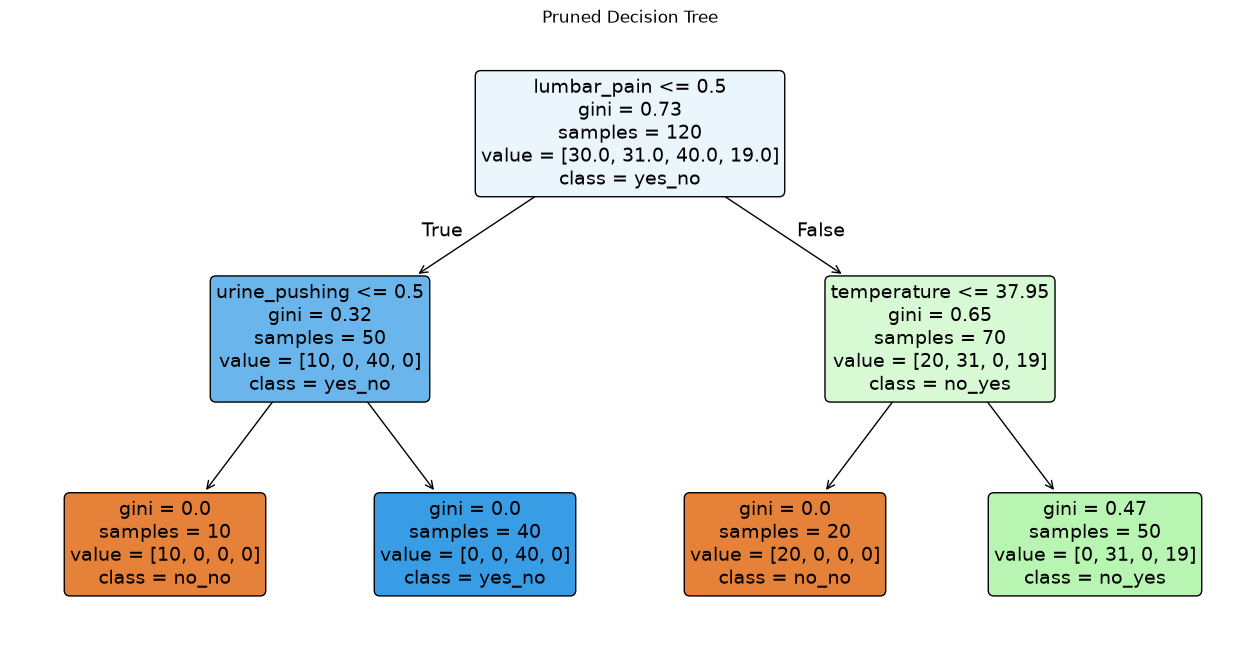

In [18]:
plt.figure(figsize=(16, 8))

plot_tree(
    pruned_model,
    feature_names=feature_names,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    precision=2
)

plt.title("Pruned Decision Tree")
plt.show()

#### Pruned Rule 1

IF lumbar_pain = no
AND urine_pushing = no

THEN bladder_inflammation = no
AND nephritis = no

#### Pruned Rule 2

IF lumbar_pain = no
AND urine_pushing = yes

THEN bladder_inflammation = yes
AND nephritis = no

#### Pruned Rule 3

IF lumbar_pain = yes
AND temperature <= 37.95

THEN bladder_inflammation = no
AND nephritis = no

#### Pruned Rule 4

IF lumbar_pain = yes
AND temperature > 37.95

THEN bladder_inflammation = no
AND nephritis = yes

## 2. The LASSO and Boosting for Regression

### 2(a) Load and Split the Communities and Crime Data

In [19]:
column_names = []

with open("Data/communities.names", "r") as file:
    for line in file:
        if line.startswith("@attribute"):
            column_names.append(line.split()[1])

print(len(column_names))

128


In [20]:
crime_data = pd.read_csv(
    "Data/communities.data",
    header=None,
    names=column_names,
    na_values="?"
)

crime_data.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [21]:
na_values="?"

In [22]:
crime_data.shape

(1994, 128)

In [23]:
train_data = crime_data.iloc[:1495].copy()
test_data = crime_data.iloc[1495:].copy()

In [24]:
print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

Training data shape: (1495, 128)
Test data shape: (499, 128)


### 2(b) Handle Missing Values and Remove Non-Predictive Features

In [25]:
non_predictive_features = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

target = "ViolentCrimesPerPop"

In [26]:
X_train = train_data.drop(
    columns=non_predictive_features + [target]
)

X_test = test_data.drop(
    columns=non_predictive_features + [target]
)

y_train = train_data[target]
y_test = test_data[target]

In [27]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1495, 122)
X_test shape: (499, 122)
y_train shape: (1495,)
y_test shape: (499,)


In [28]:
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

Missing values in X_train: 27633
Missing values in X_test: 9218


In [29]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="mean")

In [30]:
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

In [31]:
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [32]:
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


### 2(c) Plot a Correlation Matrix

In [33]:
import seaborn as sns
correlation_matrix = X_train.corr()

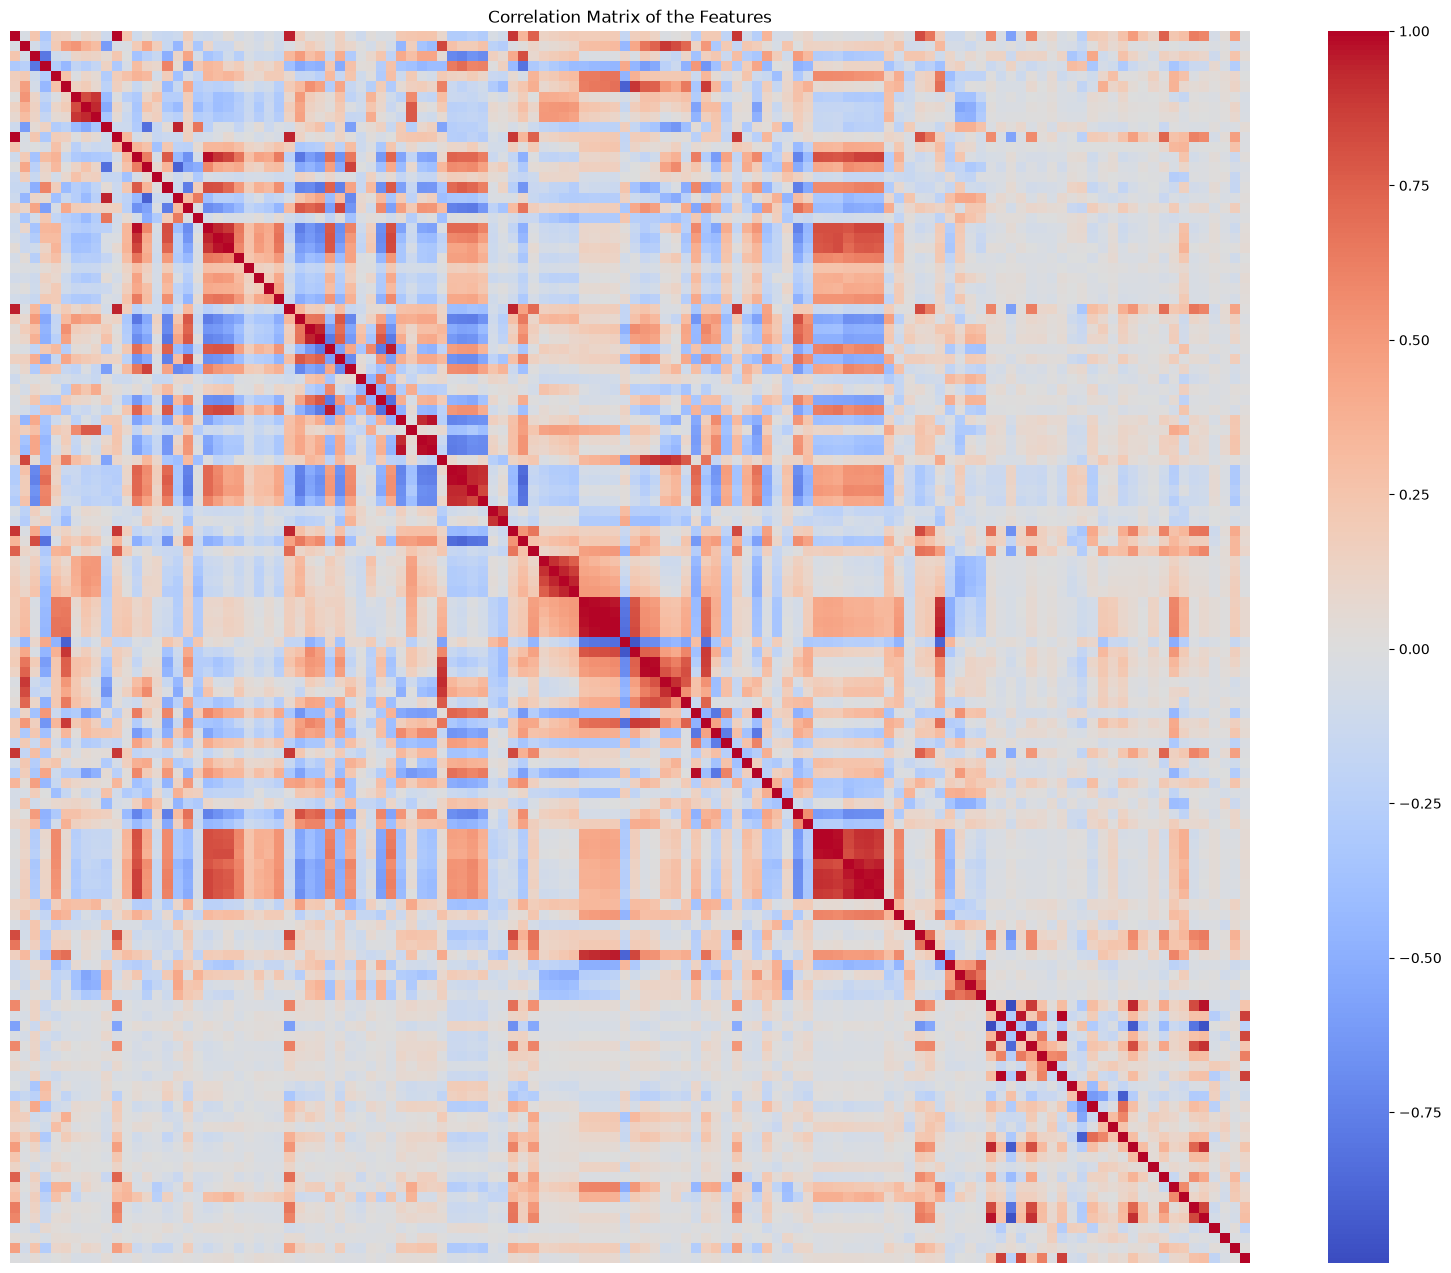

In [34]:
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of the Features")
plt.show()

### 2(d) Calculate the Coefficient of Variation

In [35]:
feature_means = X_train.mean()
feature_std = X_train.std()
cv_values = feature_std / feature_means

In [36]:
cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_std,
    "CV": cv_values
})

cv_table = cv_table.sort_values(
    by="CV",
    ascending=False
)

cv_table.head(11)

,mean,sample_std,CV
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461
HousVacant,0.076475,0.150538,1.968467
LandArea,0.064107,0.105482,1.645408


### 2(e) Select Features with the Highest CV

In [37]:
top_features = cv_table.head(11).index.tolist()

print(top_features)

['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


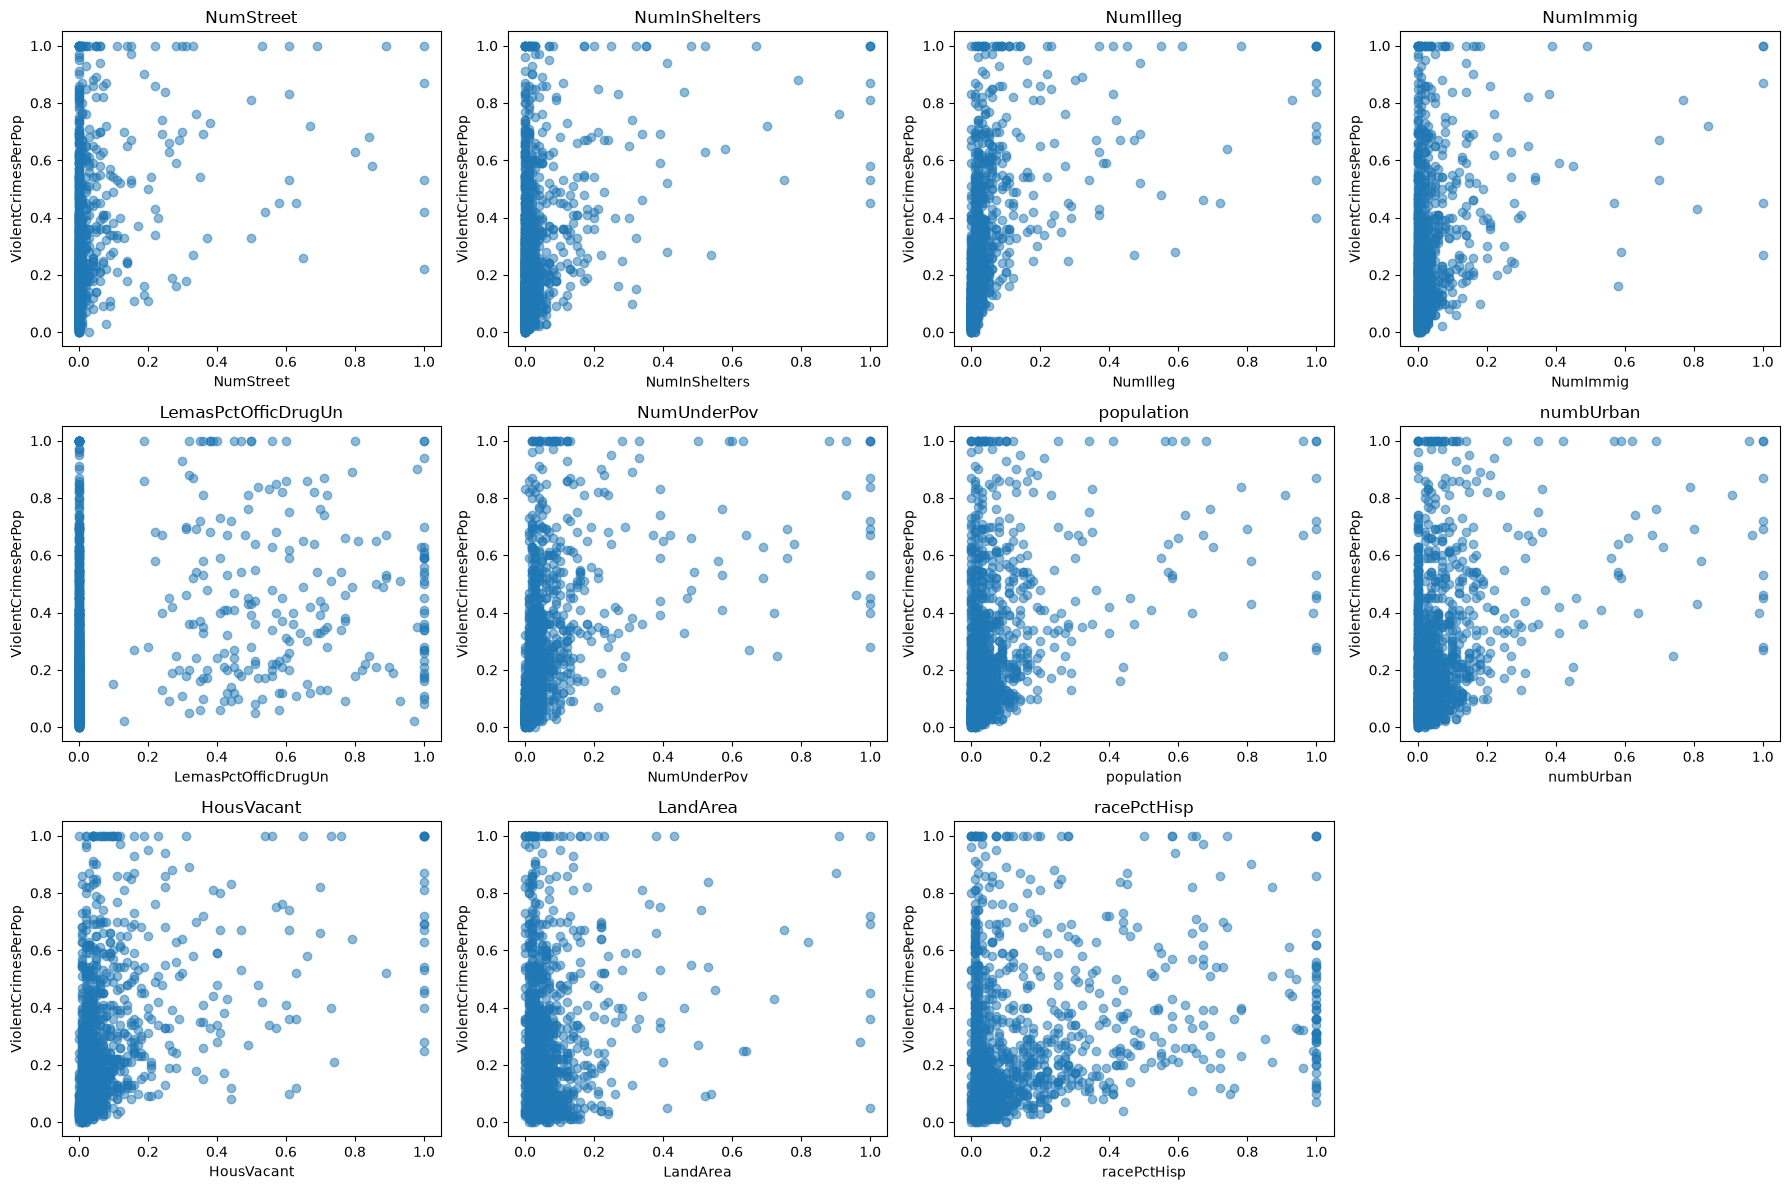

In [38]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(18, 12)
)

axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train[feature],
        y_train,
        alpha=0.5
    )
    
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")
    axes[i].set_title(feature)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

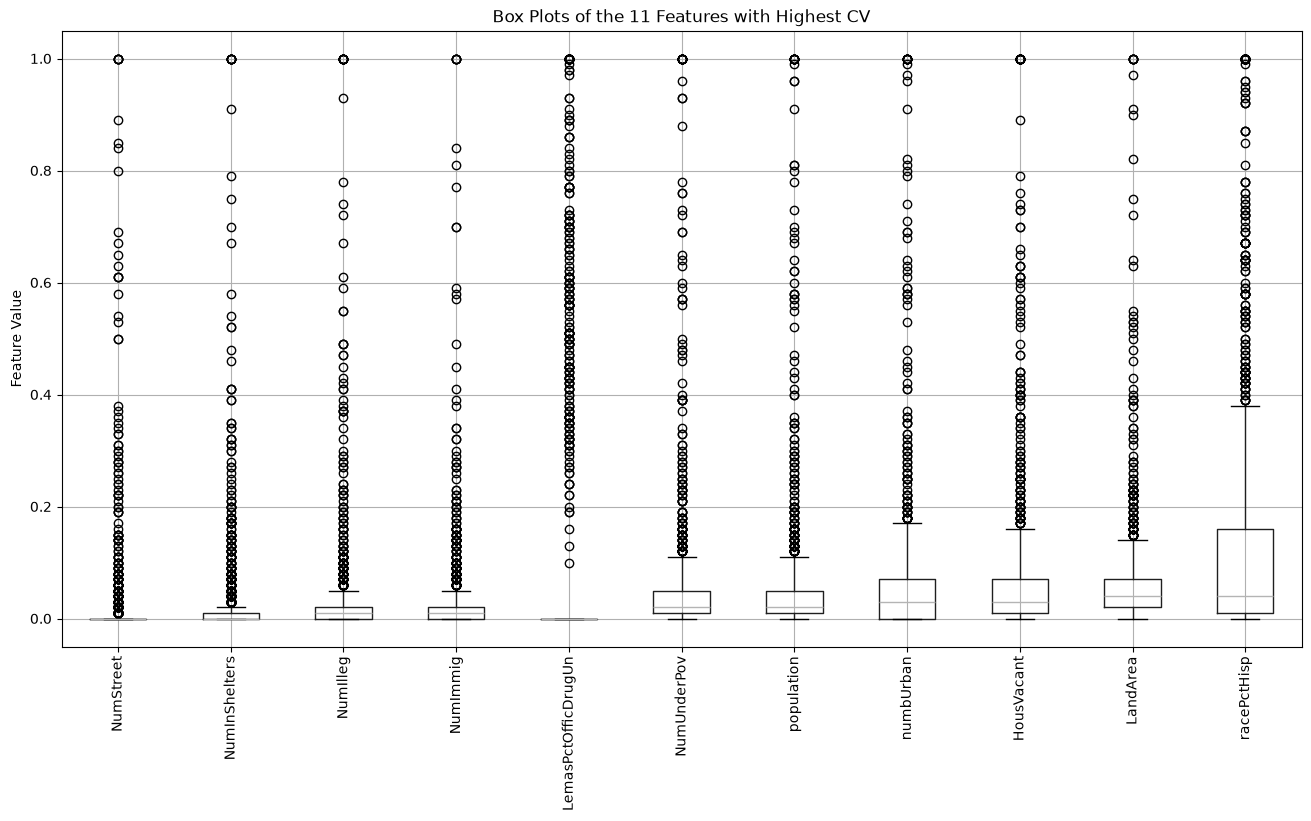

In [39]:
plt.figure(figsize=(16, 8))

X_train[top_features].boxplot()

plt.xticks(rotation=90)
plt.title("Box Plots of the 11 Features with Highest CV")
plt.ylabel("Feature Value")
plt.show()

No. The scatter plots show the general relationship between the selected features and ViolentCrimesPerPop, but they do not prove statistical significance. 

Most of the features have many observations close to zero and some outliers. Some features may show a possible positive relationship with the response variable, but the points are widely scattered. 

Therefore, statistical tests, p-values, confidence intervals, or model performance comparisons would be needed to determine whether these features are significant.

### 2(f) Fit a Linear Regression Model Using Least Squares

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

test_mse = mean_squared_error(y_test, y_pred)
print("Test MSE:", test_mse)

test_rmse = np.sqrt(test_mse)
print("Test RMSE:", test_rmse)

Test MSE: 0.018141971135530104
Test RMSE: 0.1346921346461259


I fitted a linear regression model using the least squares method. 
The test MSE is approximately 0.0181, and the test RMSE is approximately 0.1347.

### 2(g) Fit a Ridge Regression Model

In [41]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error

alphas = np.logspace(-4, 4, 100)

ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train, y_train)

print("Selected lambda:", ridge_model.alpha_)

Selected lambda: 2.310129700083163


In [42]:
ridge_pred = ridge_model.predict(X_test)

ridge_test_mse = mean_squared_error(
    y_test,
    ridge_pred
)

print("Ridge Test MSE:", ridge_test_mse)

Ridge Test MSE: 0.01759961379245253


I used five-fold cross-validation to select the regularization parameter lambda. 
The selected lambda was approximately 2.31. 
The Ridge regression model achieved a test MSE of approximately 0.0176.

### 2(h) Fit LASSO Regression Models

In [43]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

alphas = np.logspace(-4, 1, 100)

lasso_raw = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100000,
    random_state=42
)

lasso_raw.fit(X_train, y_train)

print("Selected lambda:", lasso_raw.alpha_)

Selected lambda: 0.0001261856883066021


In [44]:
lasso_raw_pred = lasso_raw.predict(X_test)

lasso_raw_mse = mean_squared_error(
    y_test,
    lasso_raw_pred
)

print("LASSO Test MSE:", lasso_raw_mse)

LASSO Test MSE: 0.01773332732423331


In [45]:
selected_raw_features = X_train.columns[
    np.abs(lasso_raw.coef_) > 1e-8
]

print("Number of selected features:", len(selected_raw_features))
print("Selected features:")
print(selected_raw_features.tolist())

Number of selected features: 75
Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'Pct

In [46]:
scaler = StandardScaler()

X_train_standardized = scaler.fit_transform(X_train)
X_test_standardized = scaler.transform(X_test)

scaler.fit_transform(X_train)
scaler.transform(X_test)

lasso_standardized = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100000,
    random_state=42
)

lasso_standardized.fit(
    X_train_standardized,
    y_train
)

print(
    "Selected standardized lambda:",
    lasso_standardized.alpha_
)

Selected standardized lambda: 0.0008111308307896872


In [47]:
lasso_standardized_pred = (
    lasso_standardized.predict(X_test_standardized)
)

lasso_standardized_mse = mean_squared_error(
    y_test,
    lasso_standardized_pred
)

print(
    "Standardized LASSO Test MSE:",
    lasso_standardized_mse
)

Standardized LASSO Test MSE: 0.017792464117509624


In [48]:
selected_standardized_features = X_train.columns[
    np.abs(lasso_standardized.coef_) > 1e-8
]

print(
    "Number of selected standardized features:",
    len(selected_standardized_features)
)

print("Selected standardized features:")
print(selected_standardized_features.tolist())

Number of selected standardized features: 73
Selected standardized features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwF

In [49]:
comparison = pd.DataFrame({
    "Model": [
        "LASSO - Original Features",
        "LASSO - Standardized Features"
    ],
    "Selected Lambda": [
        lasso_raw.alpha_,
        lasso_standardized.alpha_
    ],
    "Test MSE": [
        lasso_raw_mse,
        lasso_standardized_mse
    ],
    "Number of Selected Features": [
        len(selected_raw_features),
        len(selected_standardized_features)
    ]
})

comparison

,Model,Selected Lambda,Test MSE,Number of Selected Features
0,LASSO - Original Features,0.000126,0.017733,75
1,LASSO - Standardized Features,0.000811,0.017792,73


The LASSO model using the original features selected 75 variables and achieved a test MSE of 0.017733.

The LASSO model using standardized features selected 73 variables and achieved a test MSE of 0.017792.

The two models have very similar test errors. The model using the original features has a slightly lower test MSE by approximately 0.000059. However, the standardized model selected two fewer variables, so it produced a slightly simpler model.

### 2(i) Fit a Principal Component Regression Model

In [50]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [51]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mse = []

for m in range(1, X_train_pca.shape[1] + 1):
    linear_model = LinearRegression()
    
    scores = cross_val_score(
        linear_model,
        X_train_pca[:, :m],
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error"
    )
    
    cv_mse.append(-scores.mean())

best_m = np.argmin(cv_mse) + 1

print("Best number of components:", best_m)
print("Best cross-validation MSE:", cv_mse[best_m - 1])

Best number of components: 93
Best cross-validation MSE: 0.020253095348205127


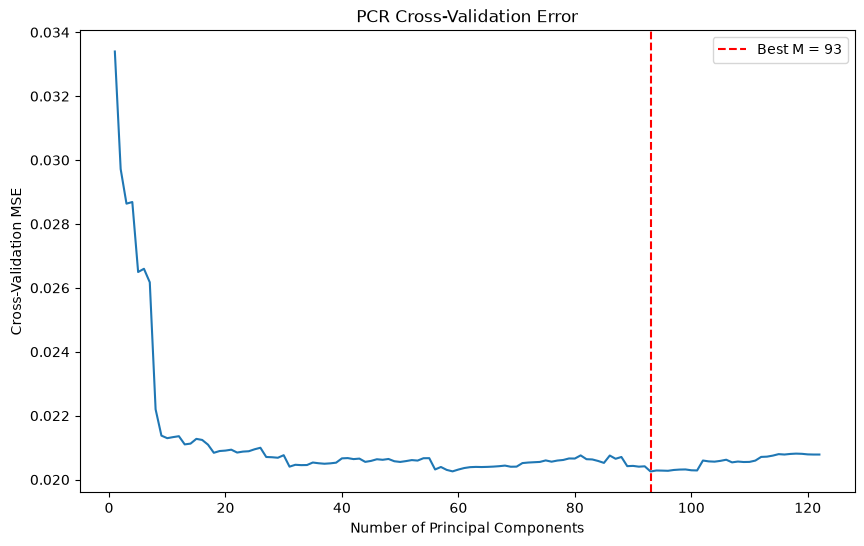

In [52]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cv_mse) + 1),
    cv_mse
)

plt.axvline(
    best_m,
    color="red",
    linestyle="--",
    label=f"Best M = {best_m}"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cross-Validation MSE")
plt.title("PCR Cross-Validation Error")
plt.legend()
plt.show()

In [53]:
pcr_model = LinearRegression()

pcr_model.fit(
    X_train_pca[:, :best_m],
    y_train
)

pcr_pred = pcr_model.predict(
    X_test_pca[:, :best_m]
)

pcr_test_mse = mean_squared_error(
    y_test,
    pcr_pred
)

print("PCR Test MSE:", pcr_test_mse)

PCR Test MSE: 0.018367590865641097


In [54]:
pcr_test_rmse = np.sqrt(pcr_test_mse)

print("PCR Test RMSE:", pcr_test_rmse)

PCR Test RMSE: 0.1355270853580239


I used five-fold cross-validation to choose the number of principal components. 
The selected number of components was M = 93. 
The PCR model achieved a test MSE of approximately 0.0184 and a test RMSE of approximately 0.1355.

### 2(j) Fit an L1-Penalized Gradient Boosting Tree Using XGBoost

In [55]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [56]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=1
)

alpha_values = [
    0,
    0.001,
    0.01,
    0.1,
    1,
    10
]

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={
        "reg_alpha": alpha_values
    },
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'reg_alpha': [0, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed 

In [57]:
print("Best alpha:", grid_search.best_params_["reg_alpha"])
print("Best CV MSE:", -grid_search.best_score_)

Best alpha: 1
Best CV MSE: 0.019938069117764908


In [58]:
xgb_model_best = grid_search.best_estimator_

xgb_pred = xgb_model_best.predict(X_test)

xgb_test_mse = mean_squared_error(
    y_test,
    xgb_pred
)

print("XGBoost Test MSE:", xgb_test_mse)

XGBoost Test MSE: 0.01569703069743588


In [59]:
xgb_test_rmse = np.sqrt(xgb_test_mse)

print("XGBoost Test RMSE:", xgb_test_rmse)

XGBoost Test RMSE: 0.12528779149396752


I used five-fold cross-validation to select the L1 regularization parameter alpha. 
The best value of alpha was 1. 
The XGBoost model achieved a test MSE of approximately 0.0157 and a test RMSE of approximately 0.1253.